In [113]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [132]:
def gamma_transform(img, gamma):
    img_float = img.astype(np.float32) / 255.0 
    corrected = 255.0 * (img_float ** gamma)
    return np.clip(corrected, 0, 255).astype(np.uint8)

def plot_hist(img,title):
    plt.figure(figsize=(8,5))
    if img.ndim == 2:
        hist = np.bincount(img.ravel(),minlength=256)
        plt.plot(hist,color='black',label='BLACK')
    else:
        for idx, color in enumerate(['red','green','blue']):
            hist = cv2.calcHist([img],[idx],None, [256], [0,256])
            plt.plot(hist,color=color,label=color.upper())
    plt.xlabel(f'Pixel')
    plt.ylabel('Instensity')
    plt.title(title)
    plt.xlim(0,256)
    plt.legend()
    plt.show()

def show_images(imgs,titles):
    plt.figure(figsize=(4*len(imgs),5))
    for idx, (img,title) in enumerate(zip(imgs,titles),start =1):
        plt.subplot(1,len(imgs),idx)
        if img.ndim == 2:
            plt.imshow(img,cmap ='gray')
        else:
            plt.imshow(img)
        plt.title(title)
        plt.axis('off')
    plt.show()


In [133]:
fp = './pic1.png'
img = cv2.imread(fp,cv2.IMREAD_COLOR)
print(img.shape)

(400, 600, 3)


In [134]:
img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

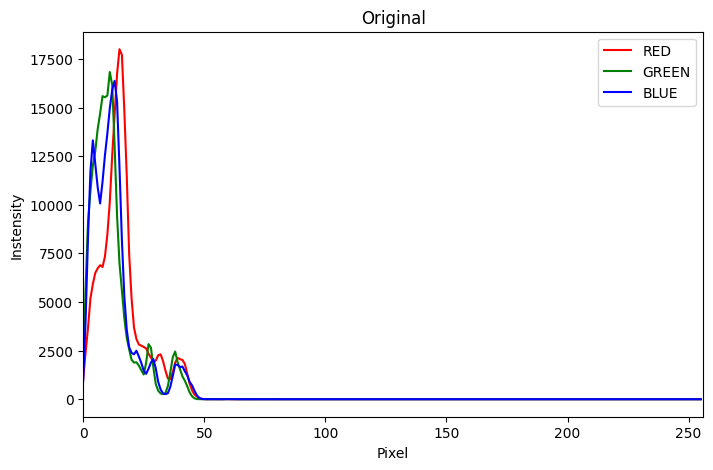

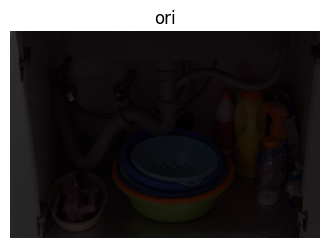

In [135]:
plot_hist(img,'Original')
show_images([img],['ori'])

In [162]:
gamma_same = gamma_transform(img,0.3)

In [163]:
r,g,b = cv2.split(img)
gamma_r = gamma_transform(r,0.3)
gamma_g = gamma_transform(g,0.27)
gamma_b = gamma_transform(b,0.28)

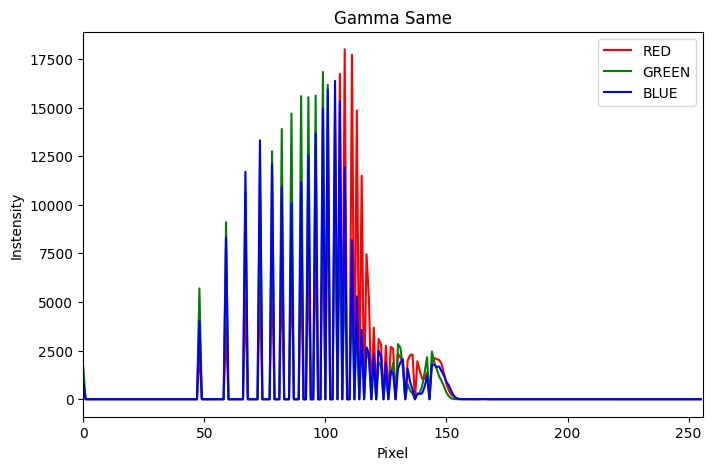

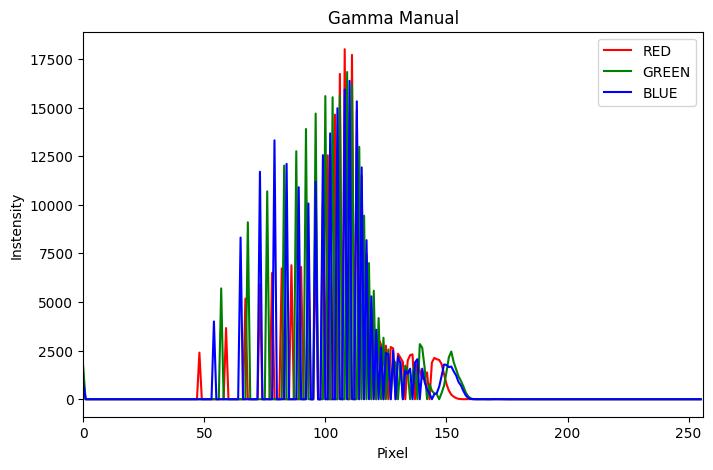

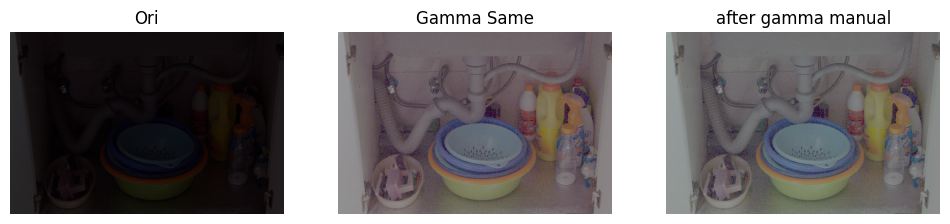

In [167]:
rgb_gamma = cv2.merge((gamma_r,gamma_g,gamma_b))
plot_hist(gamma_same,"Gamma Same")
plot_hist(rgb_gamma,"Gamma Manual")
show_images([img,gamma_same,rgb_gamma],['Ori','Gamma Same','after gamma manual'])